# Programming vs Learning: When to Calculate vs When to Learn

## For Clinicians and Health-System Leaders

Welcome to this introduction to **artificial intelligence and machine learning**, written for
clinicians, informaticians and the people who lead health systems.

### The Fundamental Question

You solve complex problems every day on the ward, in clinic and in the boardroom. But have you
ever stopped to think about **how** you solve them?

There are essentially **two approaches** to solving any problem:

1. **📐 EXPLICIT PROGRAMMING**: When we know the rules, the formula, the physiology
2. **🧠 MACHINE LEARNING**: When the patterns are too complex for explicit rules

Today we explore both approaches using familiar clinical examples, so you can tell
**when to calculate** from **when to learn from data**.

> **About the data.** Every patient in this notebook is simulated from published reference
> ranges and published risk factors. No real or identifiable patient data is used anywhere in
> this course.

---


## Setup and Imports

Let's start by importing the libraries we'll need for our clinical examples.


In [1]:
# Core libraries for calculations and data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Interactive widgets for hands-on exploration
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown
import warnings
warnings.filterwarnings('ignore')

# Visualization settings
plt.style.use('default')
sns.set_palette("viridis")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

print("🩺 Clinical AI Workshop - Libraries Loaded Successfully!")
print("Ready to explore Programming vs Learning approaches...")


🩺 Clinical AI Workshop - Libraries Loaded Successfully!
Ready to explore Programming vs Learning approaches...


---
# Part 1: When We Know the Rules (Explicit Programming)

A great deal of medicine rests on published, deterministic equations. When physiology and
measurement are well characterized, a committee of experts derives a formula, validates it in
large cohorts, and from then on every clinician **calculates** the answer. Two patients with the
same inputs get the same number, today and in ten years' time.

Let's work through two equations you have almost certainly used.


## Example 1: Estimated GFR (Kidney Function) Calculator

The **CKD-EPI 2021 creatinine equation** (Inker et al., *New England Journal of Medicine*, 2021)
tells us exactly how to estimate glomerular filtration rate from a serum creatinine:

### eGFR = 142 × min(Scr/κ, 1)^α × max(Scr/κ, 1)^(−1.200) × 0.9938^Age × 1.012 [if female]

Where:
- **Scr** = serum creatinine in **mg/dL**, the unit the equation was published in
- **κ** = 0.7 (female) or 0.9 (male)
- **α** = −0.241 (female) or −0.302 (male)
- **Age** = age in years
- Result is in **mL/min/1.73 m²**

Canadian laboratories report creatinine in **µmol/L**. The calculator below takes µmol/L, the
number you see on the lab result, and converts it before applying the equation:

**Scr (mg/dL) = creatinine (µmol/L) ÷ 88.4**

So κ = 0.7 and 0.9 mg/dL correspond to about 62 and 80 µmol/L.

This is the equation most laboratories now report alongside every creatinine result. It is
**deterministic**: give it a creatinine, an age and a sex, and it returns the same number every
time, with no training data and no uncertainty of its own.

### Slider Effects on eGFR

| Slider | What it controls | Effect on eGFR |
|--------|------------------|----------------|
| **Creatinine** | Serum creatinine, µmol/L — the waste product the kidney clears | ↑ Creatinine = ↓ eGFR (steeply) |
| **Age** | Patient age in years | ↑ Age = ↓ eGFR (0.9938 per year, about 0.6% a year) |
| **Sex** | Sets κ and α, and applies the 1.012 female coefficient | Female = slightly ↑ eGFR at the same creatinine |

Creatinine dominates: the exponent −1.200 above the κ threshold means eGFR falls roughly as the
inverse of creatinine. Age is a gentle, steady decline. Sex is a small correction.

The 2021 equation deliberately **removed the race coefficient** that appeared in earlier versions.


In [2]:
# CKD stage bands from KDIGO: (lower, upper, code, description, colour)
CKD_BANDS = [
    (90, 150, 'G1',  'Normal or high',       '#2e7d32'),
    (60,  90, 'G2',  'Mildly decreased',     '#7cb342'),
    (45,  60, 'G3a', 'Mild to moderate',     '#fdd835'),
    (30,  45, 'G3b', 'Moderate to severe',   '#fb8c00'),
    (15,  30, 'G4',  'Severely decreased',   '#e53935'),
    (0,   15, 'G5',  'Kidney failure',       '#8e24aa'),
]

# Creatinine conversion: 1 mg/dL = 88.4 umol/L
UMOL_PER_MG_DL = 88.4


def calculate_egfr(creatinine, age, sex):
    """
    Estimated GFR from the CKD-EPI 2021 creatinine equation (Inker et al., NEJM 2021).

    eGFR = 142 * min(Scr/k, 1)**a * max(Scr/k, 1)**-1.200 * 0.9938**age * 1.012 (if female)

      k = 0.7 for females, 0.9 for males
      a = -0.241 for females, -0.302 for males
      Scr = serum creatinine in mg/dL

    creatinine is in umol/L, as Canadian labs report it. The published constants are in
    mg/dL, so it is converted first (1 mg/dL = 88.4 umol/L).

    Returns mL/min/1.73 m2. Accepts a scalar or an array of creatinine values.
    """
    kappa = 0.7 if sex == 'Female' else 0.9
    alpha = -0.241 if sex == 'Female' else -0.302

    scr_mg_dl = np.asarray(creatinine, dtype=float) / UMOL_PER_MG_DL
    ratio = scr_mg_dl / kappa
    egfr = (142.0
            * np.minimum(ratio, 1.0) ** alpha
            * np.maximum(ratio, 1.0) ** -1.200
            * 0.9938 ** age)
    if sex == 'Female':
        egfr = egfr * 1.012

    return egfr.item() if np.ndim(egfr) == 0 else egfr


def ckd_stage(egfr):
    """Return the (code, description, colour) KDIGO band for an eGFR value."""
    for lo, hi, code, label, colour in CKD_BANDS:
        if egfr >= lo:
            return code, label, colour
    return 'G5', 'Kidney failure', '#8e24aa'


def renal_dosing_note(egfr):
    """The everyday consequence of the number: does prescribing have to change?"""
    if egfr >= 60:
        return ('Standard dosing', 'Renally cleared drugs can usually be given at full dose.')
    if egfr >= 30:
        return ('Review renally cleared drugs',
                'Check each agent; several need a lower dose or a longer interval.')
    if egfr >= 15:
        return ('Dose reduction required',
                'Below 30 many drugs need reduction or avoidance (metformin, most DOACs, several antibiotics).')
    return ('Specialist input required',
            'Below 15 most renally cleared drugs are contraindicated or need renal-replacement dosing.')


def interactive_egfr_calculator(creatinine=88, age=62, sex='Female'):
    egfr = calculate_egfr(creatinine, age, sex)
    code, label, colour = ckd_stage(egfr)
    dose_headline, dose_detail = renal_dosing_note(egfr)

    kappa = 0.7 if sex == 'Female' else 0.9
    alpha = -0.241 if sex == 'Female' else -0.302
    female_coeff = 1.012 if sex == 'Female' else 1.0

    # Same layout as before: wide curve on top, gauge bottom left, results bottom right
    fig = plt.figure(figsize=(16, 10))
    ax1 = fig.add_subplot(2, 2, (1, 2))   # eGFR curve - wide, top row
    ax2 = fig.add_subplot(2, 2, 3)        # stage gauge - bottom left
    ax3 = fig.add_subplot(2, 2, 4)        # results - bottom right

    # ===== eGFR AGAINST CREATININE FOR THIS PATIENT =====
    scr_axis = np.linspace(35, 530, 400)
    egfr_curve = calculate_egfr(scr_axis, age, sex)

    y_top = 150
    for lo, hi, band_code, band_label, band_colour in CKD_BANDS:
        ax1.axhspan(lo, min(hi, y_top), color=band_colour, alpha=0.16, zorder=0)
        ax1.text(532, (lo + min(hi, y_top)) / 2, band_code, va='center', ha='left',
                 fontsize=10, fontweight='bold', color=band_colour)

    ax1.plot(scr_axis, egfr_curve, color='#1a237e', linewidth=3, zorder=3,
             label='CKD-EPI 2021 equation')
    ax1.plot([creatinine], [egfr], 'o', markersize=15, color='black', zorder=5,
             label='This patient')
    ax1.vlines(creatinine, 0, egfr, color='black', linestyle='--', linewidth=1.5, zorder=4)
    ax1.hlines(egfr, 35, creatinine, color='black', linestyle='--', linewidth=1.5, zorder=4)
    ax1.annotate(f'{egfr:.0f} mL/min/1.73 m²',
                 xy=(creatinine, egfr), xytext=(creatinine + 40, egfr + 18),
                 fontsize=12, fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))

    ax1.set_xlim(35, 530)
    ax1.set_ylim(0, y_top)
    ax1.set_xlabel('Serum creatinine (µmol/L)', fontsize=12)
    ax1.set_ylabel('eGFR (mL/min/1.73 m²)', fontsize=12)
    ax1.set_title(f'eGFR against creatinine — {sex.lower()}, age {age}, with KDIGO stage bands',
                  fontsize=14, fontweight='bold')
    ax1.legend(loc='upper right', fontsize=10)
    ax1.grid(True, alpha=0.3)

    # ===== STAGE GAUGE =====
    for lo, hi, band_code, band_label, band_colour in CKD_BANDS:
        top = min(hi, y_top)
        highlight = (band_code == code)
        ax2.bar(0, top - lo, bottom=lo, width=0.9, color=band_colour,
                alpha=0.95 if highlight else 0.30,
                edgecolor='black' if highlight else 'none',
                linewidth=2.5 if highlight else 0)
        ax2.text(0.52, (lo + top) / 2, f'{band_code}  {band_label}', va='center', ha='left',
                 fontsize=10, fontweight='bold' if highlight else 'normal')

    ax2.plot([-0.45, 0.45], [egfr, egfr], color='black', linewidth=3, zorder=6)
    ax2.annotate(f'{egfr:.0f}', xy=(-0.45, egfr), xytext=(-0.95, egfr),
                 va='center', ha='right', fontsize=13, fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))

    ax2.set_xlim(-1.4, 2.4)
    ax2.set_ylim(0, y_top)
    ax2.set_xticks([])
    ax2.set_ylabel('eGFR (mL/min/1.73 m²)', fontsize=11)
    ax2.set_title(f'CKD stage: {code} — {label}', fontsize=14, fontweight='bold')

    # ===== RESULTS PANEL =====
    ax3.axis('off')
    ax3.text(0.5, 0.97, 'eGFR Calculation (CKD-EPI 2021)', ha='center', fontsize=14,
             fontweight='bold', transform=ax3.transAxes)

    scr_mg_dl = creatinine / UMOL_PER_MG_DL
    ratio = scr_mg_dl / kappa
    formula_text = f"""
  eGFR = 142 x min(Scr/k,1)^a x max(Scr/k,1)^-1.200
              x 0.9938^Age x {female_coeff:.3f}

  Creatinine = {creatinine:.0f} µmol/L  ÷ 88.4
  Scr  = {scr_mg_dl:.2f} mg/dL      Age = {age} yr
  Sex  = {sex}     k = {kappa}   a = {alpha}

  Scr/k          = {ratio:.3f}
  min(Scr/k,1)^a = {min(ratio, 1.0) ** alpha:.4f}
  max(Scr/k,1)^-1.200 = {max(ratio, 1.0) ** -1.200:.4f}
  0.9938^{age}      = {0.9938 ** age:.4f}

  ────────────────────────────
  eGFR = {egfr:.1f} mL/min/1.73 m²
  Stage = {code} ({label})
    """

    ax3.text(0.03, 0.89, formula_text, transform=ax3.transAxes, fontsize=10,
             verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))

    ax3.text(0.03, 0.16, 'Prescribing implication', transform=ax3.transAxes,
             fontsize=12, fontweight='bold')
    ax3.text(0.03, 0.10, dose_headline, transform=ax3.transAxes, fontsize=11,
             fontweight='bold', color=colour)
    ax3.text(0.03, 0.01, dose_detail, transform=ax3.transAxes, fontsize=9.5,
             style='italic', va='bottom', wrap=True)

    plt.tight_layout()
    plt.show()

    print(f"🩺 RESULTS: eGFR {egfr:.1f} mL/min/1.73 m² — CKD stage {code} ({label})")
    print(f"   💊 {dose_headline}: {dose_detail}")


print("🎛️ Interactive eGFR Calculator (CKD-EPI 2021)")
print("   • Creatinine → moves the patient along the curve (the dominant term)")
print("   • Age → shifts the whole curve down by 0.9938 per year")
print("   • Sex → changes k and a, and applies the 1.012 female coefficient")
print()

interact(interactive_egfr_calculator,
         creatinine=IntSlider(value=88, min=35, max=530, step=5, description='Creat (µmol/L)', style={'description_width': 'initial'}),
         age=IntSlider(value=62, min=18, max=95, step=1, description='Age (yr)'),
         sex=Dropdown(options=['Female', 'Male'], value='Female', description='Sex'));


🎛️ Interactive eGFR Calculator (CKD-EPI 2021)
   • Creatinine → moves the patient along the curve (the dominant term)
   • Age → shifts the whole curve down by 0.9938 per year
   • Sex → changes k and a, and applies the 1.012 female coefficient



interactive(children=(IntSlider(value=88, description='Creat (µmol/L)', max=530, min=35, step=5, style=SliderS…

## Example 2: Cardiac Cycle Timing and the Corrected QT

Cardiac electrophysiology gives us exact arithmetic for the timing of a heartbeat.

### RR interval (ms) = 60000 / heart rate (bpm)

The RR interval is simply the time between two successive R peaks, and it follows from the rate
by division — nothing is estimated.

### Bazett's formula: QTc = QT / √(RR in seconds)

**Bazett (1920)** corrects the measured QT interval for heart rate, because the QT naturally
shortens as the heart speeds up. Without the correction you cannot compare a QT measured at 50 bpm
with one measured at 110 bpm.

Where:
- **QT** = measured QT interval (ms), from the start of the QRS complex to the end of the T deflection
- **RR** = RR interval in **seconds** (so RR = 60 / heart rate)
- **QTc** = rate-corrected QT (ms)

A QTc above **450 ms in men** or **460 ms in women** is conventionally called prolonged, and above
500 ms the risk of torsades de pointes rises sharply. This matters at the bedside because dozens of
common drugs prolong the QT.

Again this is **deterministic** — two clinicians with the same calipers get the same QTc.


In [3]:
def calculate_cardiac_timing(heart_rate, qt_ms):
    """
    Cardiac cycle timing from first principles.

    Parameters:
    - heart_rate: ventricular rate in beats per minute
    - qt_ms: measured QT interval in milliseconds

    Returns:
    - rr_ms: RR interval in milliseconds (60000 / heart rate)
    - rr_s: RR interval in seconds
    - qtc_ms: rate-corrected QT by Bazett's formula, QTc = QT / sqrt(RR in seconds)
    """
    rr_ms = 60000.0 / heart_rate
    rr_s = rr_ms / 1000.0
    qtc_ms = qt_ms / np.sqrt(rr_s)
    return rr_ms, rr_s, qtc_ms


def _ecg_beat(offset_s, qt_s):
    """
    One cardiac cycle, drawn as a sum of smooth deflections.

    offset_s is time in seconds measured from the onset of atrial depolarization.
    The three deflections of a normal beat are:
      P   - atrial depolarization      (small, rounded, before the QRS)
      QRS - ventricular depolarization (the tall sharp spike)
      T   - ventricular repolarization (broad, after the QRS)
    The T deflection is placed so that it ends QT seconds after the QRS onset,
    which is exactly how the QT interval is measured.
    """
    qrs_onset = 0.16                                  # PR interval, seconds

    y = 0.15 * np.exp(-0.5 * ((offset_s - 0.06) / 0.022) ** 2)                     # P
    y = y - 0.10 * np.exp(-0.5 * ((offset_s - (qrs_onset + 0.012)) / 0.008) ** 2)  # Q
    y = y + 1.00 * np.exp(-0.5 * ((offset_s - (qrs_onset + 0.030)) / 0.009) ** 2)  # R
    y = y - 0.22 * np.exp(-0.5 * ((offset_s - (qrs_onset + 0.056)) / 0.012) ** 2)  # S

    t_sigma = max(0.050, qt_s * 0.115)
    t_centre = qrs_onset + qt_s - 2.2 * t_sigma
    y = y + 0.30 * np.exp(-0.5 * ((offset_s - t_centre) / t_sigma) ** 2)           # T
    return y


QRS_ONSET_S = 0.16      # seconds from beat start to the start of the QRS complex
R_PEAK_S = 0.19         # seconds from beat start to the R peak


def interactive_ecg_calculator(heart_rate=72, qt_ms=400, sex='Female'):
    rr_ms, rr_s, qtc_ms = calculate_cardiac_timing(heart_rate, qt_ms)
    qt_s = qt_ms / 1000.0
    threshold = 460 if sex == 'Female' else 450
    prolonged = qtc_ms > threshold

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10))

    # ===== DRAWN ECG TRACE =====
    n_beats = 4
    duration = n_beats * rr_s
    t = np.linspace(0, duration, 3000)
    trace = np.zeros_like(t)
    for k in range(-1, n_beats + 2):
        trace = trace + _ecg_beat(t - k * rr_s, qt_s)

    ax1.axhline(y=0, color='black', linestyle='-', alpha=0.3, label='Isoelectric baseline')
    ax1.plot(t, trace, color='#b71c1c', linewidth=2.2, label='Simulated lead II')

    r_peaks = np.array([R_PEAK_S + k * rr_s for k in range(n_beats)])
    ax1.plot(r_peaks, [1.0] * n_beats, 'v', color='#1a237e', markersize=10, label='R peak')

    # Annotate the RR interval between the second and third R peaks
    if n_beats >= 3:
        y_rr = 1.35
        ax1.annotate('', xy=(r_peaks[2], y_rr), xytext=(r_peaks[1], y_rr),
                     arrowprops=dict(arrowstyle='<->', color='#1a237e', lw=2))
        ax1.text((r_peaks[1] + r_peaks[2]) / 2, y_rr + 0.08,
                 f'RR = {rr_ms:.0f} ms  (60000 / {heart_rate})',
                 ha='center', fontsize=12, color='#1a237e', fontweight='bold')

    # Annotate the QT interval on the second beat
    qt_start = QRS_ONSET_S + 1 * rr_s
    y_qt = -0.55
    ax1.annotate('', xy=(qt_start + qt_s, y_qt), xytext=(qt_start, y_qt),
                 arrowprops=dict(arrowstyle='<->', color='#2e7d32', lw=2))
    ax1.text(qt_start + qt_s / 2, y_qt - 0.18, f'QT = {qt_ms:.0f} ms',
             ha='center', fontsize=12, color='#2e7d32', fontweight='bold')

    ax1.text(0.01, 0.97,
             'P = atrial depolarization   QRS = ventricular depolarization   T = ventricular repolarization',
             transform=ax1.transAxes, fontsize=10, va='top', style='italic',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

    ax1.set_xlim(0, duration)
    ax1.set_ylim(-1.0, 1.75)
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Amplitude (mV)')
    ax1.set_title(f'Simulated ECG at {heart_rate} bpm', fontsize=14, fontweight='bold')
    ax1.legend(loc='upper right', fontsize=10)
    ax1.grid(True, alpha=0.3)

    # ===== TIMING BAR CHART (all in milliseconds, same scale) =====
    labels = ['RR interval\n(60000 / HR)', 'QT measured', "QTc (Bazett)"]
    values = [rr_ms, qt_ms, qtc_ms]
    colors = ['#1a237e', '#2e7d32', '#e53935' if prolonged else '#7cb342']

    bars = ax2.bar(labels, values, color=colors, alpha=0.8)
    ax2.axhline(y=threshold, color='red', linestyle='--', linewidth=2,
                label=f'Prolonged QTc threshold, {sex.lower()} = {threshold} ms')
    ax2.set_ylabel('Milliseconds')
    ax2.set_title('Cardiac cycle timing', fontsize=14, fontweight='bold')
    ax2.legend(loc='upper right', fontsize=10)
    ax2.grid(True, alpha=0.3)

    ax2.set_ylim(0, max(max(values), threshold) * 1.18)
    for bar, value in zip(bars, values):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width() / 2., height + max(values) * 0.025,
                 f'{value:.0f} ms', ha='center', va='bottom', fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                           edgecolor='none', alpha=0.85))

    plt.tight_layout()
    plt.show()

    print("🫀 CARDIAC CYCLE CALCULATION:")
    print(f"   💓 Heart rate: {heart_rate} bpm")
    print(f"   ⏱️  RR interval: {rr_ms:.1f} ms ({rr_s:.3f} s)")
    print(f"   📏 Measured QT: {qt_ms:.0f} ms")
    print(f"   🧮 QTc (Bazett) = {qt_ms:.0f} / sqrt({rr_s:.3f}) = {qtc_ms:.1f} ms")
    if prolonged:
        print(f"   ⚠️  PROLONGED: QTc {qtc_ms:.0f} ms exceeds the {threshold} ms threshold for a {sex.lower()} patient.")
        if qtc_ms > 500:
            print("      Above 500 ms the risk of torsades de pointes rises sharply — review QT-prolonging drugs.")
    else:
        print(f"   ✅ Within normal limits (threshold {threshold} ms for a {sex.lower()} patient).")
    print("\n💡 These are EXACT calculations from published formulas, not predictions!")


print("🫀 Interactive Cardiac Cycle Calculator")
print("See how heart rate changes the RR interval, and how Bazett's correction changes the QTc:")

interact(interactive_ecg_calculator,
         heart_rate=IntSlider(value=72, min=40, max=160, step=1, description='Heart rate'),
         qt_ms=IntSlider(value=400, min=280, max=540, step=5, description='QT (ms)'),
         sex=Dropdown(options=['Female', 'Male'], value='Female', description='Sex'));


🫀 Interactive Cardiac Cycle Calculator
See how heart rate changes the RR interval, and how Bazett's correction changes the QTc:


interactive(children=(IntSlider(value=72, description='Heart rate', max=160, min=40), IntSlider(value=400, des…

---
# Part 2: When We Don't Know the Rules (Machine Learning)

But what happens when the relationships become **too complex** for a formula?

Most of the questions that actually consume a health system have no published equation. No expert
committee has ever written down "the readmission formula", because the answer depends on dozens of
patient, treatment and social factors that interact differently in every patient. This is where
**machine learning** earns its place: we let the computer **learn the pattern** from historical
records instead of trying to legislate it.

Let's look at two examples where learning from data beats any rule we could write.


## Example 1: 30-Day Readmission Risk

**The Challenge**: whether a patient comes back within 30 days of discharge depends on many
interacting factors:
- Age and physiological reserve
- Number and severity of comorbidities
- How often they have been admitted in the past year
- Length of the index stay
- Where they are discharged to (home, home with support, rehabilitation or long-term care (LTC))
- Polypharmacy — the number of medicines on the discharge list
- Social support at home
- Frailty

Ask ten experienced clinicians to rank these and you will get ten different answers, and none of
them can write the equation down. The factors do not simply add up: frailty matters far more in an
85-year-old with eight comorbidities than in a robust 60-year-old with one.

So instead of writing a formula, we **learn the pattern** from historical discharge records.

> **Simulated data.** The 1,000 patients below are generated from published risk-factor directions
> and effect sizes. They are not real people and contain no identifiable patient information.


In [4]:
# Generate realistic synthetic discharge data
np.random.seed(42)
n_patients = 1000

# The features a discharge planner actually has in front of them
READMISSION_FEATURES = ['age', 'comorbidity_count', 'prior_admissions_12mo', 'index_los_days',
                        'discharge_destination', 'medication_count', 'social_support_score',
                        'frailty_index']

# discharge_destination is ordinal: 0 = home, 1 = home with support, 2 = rehab / long-term care
patient_records = {
    'age': np.random.uniform(45, 95, n_patients),
    'comorbidity_count': np.random.randint(0, 9, n_patients),
    'prior_admissions_12mo': np.clip(np.random.poisson(1.1, n_patients), 0, 8),
    'index_los_days': np.clip(np.random.gamma(2.2, 2.4, n_patients), 1, 30),
    'discharge_destination': np.random.choice([0, 1, 2], n_patients, p=[0.55, 0.28, 0.17]),
    'medication_count': np.random.randint(1, 21, n_patients),
    'social_support_score': np.random.uniform(1, 10, n_patients),
    'frailty_index': np.random.uniform(0, 1, n_patients),
}


def calculate_readmission_risk(age, comorbidities, prior_admissions, los, destination,
                               medications, support, frailty):
    """
    A deliberately messy readmission risk model with many interacting factors.

    This stands in for the real-world complexity that makes an explicit formula impossible:
    each factor is non-linear, and several of them modify each other. Returns the probability
    of an unplanned readmission within 30 days, as a percentage.
    """
    # Risk climbs steeply, not linearly, with age
    base_risk = 2.5 + ((age - 45) ** 1.35) * 0.030

    # Comorbidity burden compounds
    comorbidity_factor = 1 + comorbidities * 0.13 + comorbidities ** 2 * 0.008

    # Prior utilization is the single strongest signal in the literature
    prior_factor = 1 + (np.exp(prior_admissions / 4.0) - 1) * 0.35

    # A long index stay signals a complicated admission
    los_factor = 0.85 + (los / 10) * 0.30 + (los / 10) ** 2 * 0.10

    # Discharge destination: home, home with support, rehab / long-term care
    destination_factor = [1.00, 1.18, 1.42][int(destination)]

    # Polypharmacy beyond about five agents
    medication_factor = 1 + max(0.0, medications - 5) * 0.022

    # Strong social support is protective
    support_factor = 1.45 - (support / 10) * 0.55

    # Frailty amplifies everything else
    frailty_factor = 1 + frailty * 0.60

    # Interactions that no additive rule would capture
    interaction_effect = 1 + 0.12 * np.sin(age * (comorbidities + 1) / 40) * frailty

    risk = (base_risk * comorbidity_factor * prior_factor * los_factor * destination_factor
            * medication_factor * support_factor * frailty_factor * interaction_effect)

    # Individual variation: two identical patients still differ
    risk = risk * np.random.normal(1, 0.12)

    return float(np.clip(risk, 0.8, 85.0))


# Calculate a 30-day readmission risk for every simulated discharge
patient_records['readmission_risk_pct'] = [
    calculate_readmission_risk(
        patient_records['age'][i],
        patient_records['comorbidity_count'][i],
        patient_records['prior_admissions_12mo'][i],
        patient_records['index_los_days'][i],
        patient_records['discharge_destination'][i],
        patient_records['medication_count'][i],
        patient_records['social_support_score'][i],
        patient_records['frailty_index'][i]
    ) for i in range(n_patients)
]

# Convert to DataFrame
df_patients = pd.DataFrame(patient_records)

print("🩺 Generated Synthetic Discharge Data (simulated, no real patient data)")
print(f"📊 {len(df_patients)} discharges with complex readmission patterns")
print(f"🔁 Mean 30-day readmission risk: {df_patients['readmission_risk_pct'].mean():.1f}%"
      f"  (range {df_patients['readmission_risk_pct'].min():.1f}% to {df_patients['readmission_risk_pct'].max():.1f}%)")
print("\n📋 Sample of discharge records:")
display(df_patients.head(10).round(2))


🩺 Generated Synthetic Discharge Data (simulated, no real patient data)
📊 1000 discharges with complex readmission patterns
🔁 Mean 30-day readmission risk: 18.9%  (range 2.8% to 85.0%)

📋 Sample of discharge records:


,age,comorbidity_count,prior_admissions_12mo,index_los_days,discharge_destination,medication_count,social_support_score,frailty_index,readmission_risk_pct
0,63.73,7,0,1.90,2,15,6.27,0.49,21.82
1,92.54,2,1,8.30,0,1,9.78,0.70,20.34
2,81.60,7,0,2.71,0,12,5.79,0.51,21.65
3,74.93,4,2,4.71,0,5,9.15,0.87,15.42
4,52.80,0,0,2.81,2,6,1.75,0.29,7.60
5,52.80,6,1,6.99,0,1,2.72,0.09,12.27
6,47.90,4,1,1.00,2,1,4.97,0.94,11.40
7,88.31,5,1,2.76,2,10,6.26,0.38,28.52
8,75.06,5,1,7.09,0,10,8.35,0.58,16.05
9,80.40,7,2,2.39,0,3,9.89,0.79,21.16


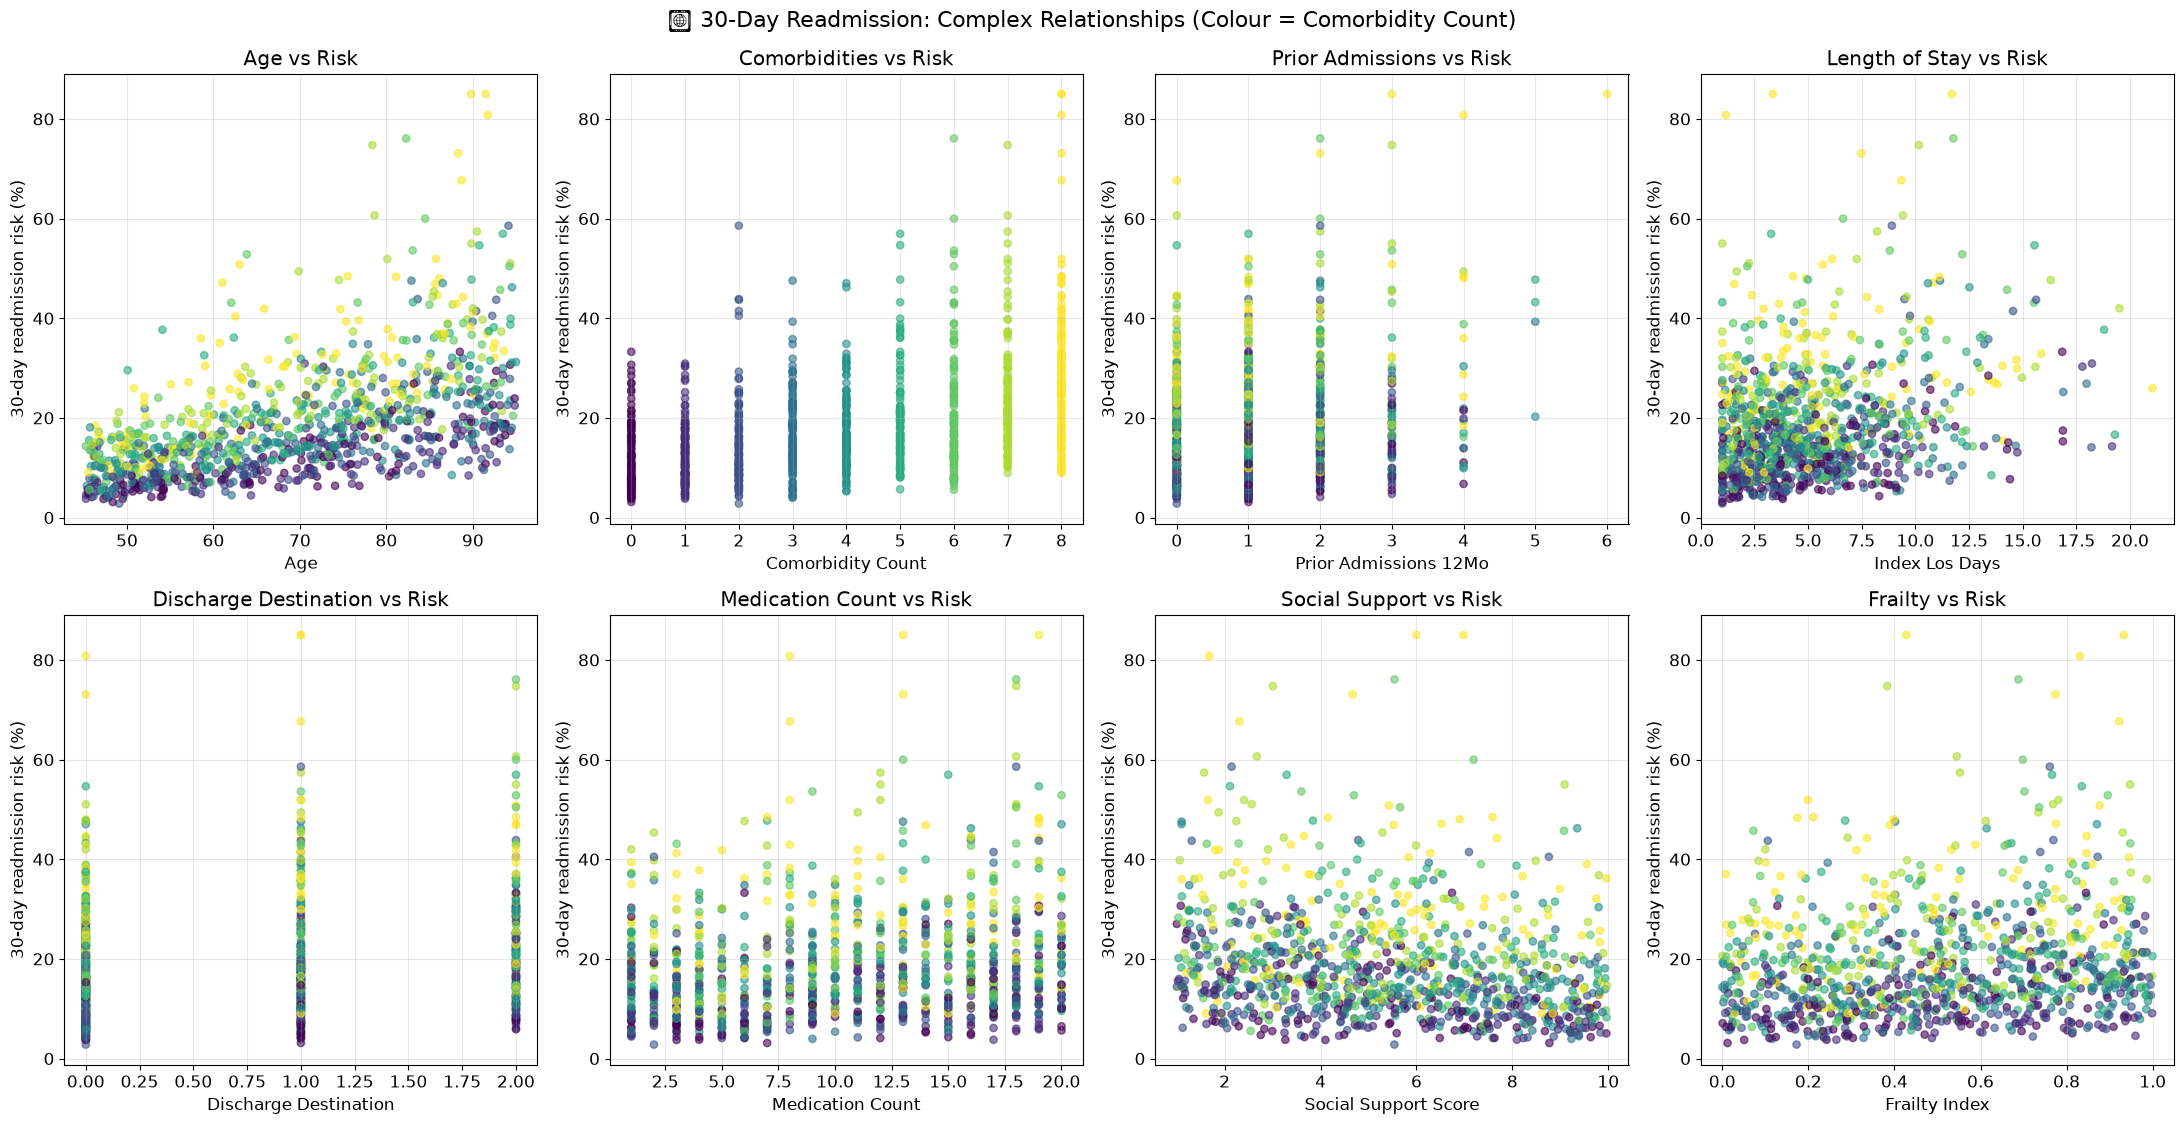

🤔 NOTICE THE COMPLEXITY:
   • No clear single relationship
   • Multiple factors interact
   • Lots of scatter between patients who look alike on paper
   • No committee could ever agree a formula for this!

💡 This is where MACHINE LEARNING becomes powerful!


In [5]:
# Visualize the complexity of the readmission problem
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
axes = axes.ravel()

titles = ['Age vs Risk', 'Comorbidities vs Risk', 'Prior Admissions vs Risk',
          'Length of Stay vs Risk', 'Discharge Destination vs Risk', 'Medication Count vs Risk',
          'Social Support vs Risk', 'Frailty vs Risk']

for i, (factor, title) in enumerate(zip(READMISSION_FEATURES, titles)):
    axes[i].scatter(df_patients[factor], df_patients['readmission_risk_pct'],
                    alpha=0.6, c=df_patients['comorbidity_count'], cmap='viridis', s=28)
    axes[i].set_xlabel(factor.replace('_', ' ').title())
    axes[i].set_ylabel('30-day readmission risk (%)')
    axes[i].set_title(title)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('🔍 30-Day Readmission: Complex Relationships (Colour = Comorbidity Count)',
             y=1.02, fontsize=16)
plt.show()

print("🤔 NOTICE THE COMPLEXITY:")
print("   • No clear single relationship")
print("   • Multiple factors interact")
print("   • Lots of scatter between patients who look alike on paper")
print("   • No committee could ever agree a formula for this!")
print("\n💡 This is where MACHINE LEARNING becomes powerful!")


In [6]:
# Now let's train a machine learning model to learn the patterns
def train_readmission_model(df, training_size=0.8):
    """
    Train a machine learning model to predict 30-day readmission risk
    """
    # Prepare features (input variables)
    features = READMISSION_FEATURES
    X = df[features]
    y = df['readmission_risk_pct']

    # Split data for training and testing
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1-training_size, random_state=42)

    # Train a Random Forest model (learns complex patterns automatically)
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    # Make predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Calculate accuracy metrics
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)

    return model, X_test, y_test, y_pred_test, train_r2, test_r2, train_mae, test_mae, features

# Interactive demonstration of learning with different amounts of data
def interactive_ml_learning_demo(training_percentage=80):
    training_size = training_percentage / 100

    # Train model
    model, X_test, y_test, y_pred_test, train_r2, test_r2, train_mae, test_mae, features = train_readmission_model(
        df_patients, training_size
    )

    # Create visualizations
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

    # 1. Actual vs Predicted
    max_risk = max(y_test.max(), y_pred_test.max())
    ax1.scatter(y_test, y_pred_test, alpha=0.6, s=50)
    ax1.plot([0, max_risk], [0, max_risk], 'r--', linewidth=2, label='Perfect Prediction')
    ax1.set_xlabel('Actual readmission risk (%)')
    ax1.set_ylabel('Predicted readmission risk (%)')
    ax1.set_title(f'Actual vs Predicted\nR² = {test_r2:.3f}, MAE = {test_mae:.2f} percentage points')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # 2. Feature Importance
    importance = model.feature_importances_
    feature_names = [f.replace('_', ' ').title() for f in features]
    bars = ax2.barh(feature_names, importance, color='skyblue')
    ax2.set_xlabel('Importance')
    ax2.set_title('Feature Importance\n(What the model learned matters most)')
    ax2.grid(True, alpha=0.3)

    # 3. Prediction Error Distribution
    errors = y_test - y_pred_test
    ax3.hist(errors, bins=30, alpha=0.7, color='lightcoral', edgecolor='black')
    ax3.axvline(x=0, color='red', linestyle='--', linewidth=2)
    ax3.set_xlabel('Prediction error (percentage points)')
    ax3.set_ylabel('Frequency')
    ax3.set_title(f'Prediction Errors\nMean Error = {errors.mean():.2f} points')
    ax3.grid(True, alpha=0.3)

    # 4. Learning Progress Simulation
    train_sizes = np.linspace(0.1, training_size, 10)
    r2_scores = []

    for size in train_sizes:
        _, _, _, _, _, r2, _, _, _ = train_readmission_model(df_patients, size)
        r2_scores.append(r2)

    ax4.plot(train_sizes * 100, r2_scores, 'o-', linewidth=3, markersize=8, color='green')
    ax4.axvline(x=training_percentage, color='red', linestyle='--', alpha=0.7, label='Current Training Size')
    ax4.set_xlabel('Training Data Used (%)')
    ax4.set_ylabel('Model Accuracy (R²)')
    ax4.set_title('Learning Curve\n(More patients = Better predictions)')
    ax4.grid(True, alpha=0.3)
    ax4.legend()

    plt.tight_layout()
    plt.show()

    print("🤖 MACHINE LEARNING RESULTS:")
    print(f"   📊 Training Data Used: {training_percentage}% ({int(len(df_patients) * training_size)} discharges)")
    print(f"   🎯 Model Accuracy (R²): {test_r2:.3f} ({test_r2*100:.1f}%)")
    print(f"   📉 Average Error: ±{test_mae:.2f} percentage points")
    print(f"   🧠 Most Important Factor: {features[np.argmax(importance)].replace('_', ' ').title()}")
    print("\n💡 The model LEARNED complex patterns that would be impossible to program explicitly!")


print("🤖 Interactive Machine Learning Demo")
print("See how the model learns better with more training data:")

interact(interactive_ml_learning_demo,
         training_percentage=IntSlider(value=80, min=20, max=95, step=5,
                                     description='Training Data %'));


🤖 Interactive Machine Learning Demo
See how the model learns better with more training data:


interactive(children=(IntSlider(value=80, description='Training Data %', max=95, min=20, step=5), Output()), _…

## Example 2: Model Drift After Deployment

**The Challenge**: a risk model that was excellent on the day it went live quietly gets worse.

This is called **model drift**, and it is the single most common reason clinical AI fails in
production. Nothing breaks; the code is unchanged; the model simply describes a population that no
longer exists. Things that shift underneath a deployed model:

- Case mix — a new service line, a closed ward next door, a changed catchment
- The patients themselves — an ageing population, a new variant, a new treatment pathway
- Documentation and coding practice — the inputs change meaning
- Clinician behaviour in response to the model itself

Here we watch a deployed 30-day readmission model over **36 months**, and see what retraining does
to it. Discrimination is measured as **AUC** (area under the ROC curve): 1.0 is perfect, 0.5 is a
coin toss.

This example sets up material later in the course on monitoring deployed models — but notice the
lesson is the same as before. No formula tells you when a model has gone stale. You learn it from
the monitoring data.


In [7]:
# Generate deployed-model monitoring data over time
np.random.seed(123)
n_months = 36  # 3 years of production monitoring

# The model was retrained at these calendar months
retrain_months = [0, 12, 24]

month = np.arange(n_months)
# Months elapsed since the most recent retrain: resets to zero at every retraining event
months_since_retrain = np.array(
    [m - max(r for r in retrain_months if r <= m) for m in month]
)

DRIFT_FEATURES = ['months_since_retrain', 'mean_patient_age', 'case_mix_novelty',
                  'admissions_per_month', 'documentation_completeness_pct']

drift_records = {
    'month': month,
    'months_since_retrain': months_since_retrain,
    # The population ages and shifts away from the training cohort
    'mean_patient_age': 68 + 2.5 * np.sin(2 * np.pi * month / 12) + np.cumsum(np.random.normal(0.06, 0.25, n_months)),
    # How unlike the training data this month's case mix is (1 = identical, 10 = wholly new)
    'case_mix_novelty': np.clip(np.random.uniform(1, 5, n_months) + months_since_retrain * 0.25, 1, 10),
    'admissions_per_month': np.random.uniform(420, 1150, n_months),
    'documentation_completeness_pct': np.clip(np.random.normal(94, 2.5, n_months), 82, 100),
}


def calculate_model_discrimination(months_since_retrain, mean_age, novelty, volume, documentation):
    """
    Complex performance-decay model for a deployed risk score.

    Returns the AUC the model achieves in a given month. Performance decays as the
    time since retraining grows and as the case mix drifts away from the training
    population, and it is restored whenever the model is retrained.
    """
    # Base decay: slow at first, then accelerating
    base_auc = 0.865 - (months_since_retrain ** 1.35) * 0.0035

    # The population drifts away from the age distribution the model was trained on
    age_factor = 1 - abs(mean_age - 68) * 0.004

    # Genuinely novel case mix hurts most
    novelty_factor = 1 - (novelty - 1) * 0.008

    # Larger monthly cohorts give slightly more stable estimates
    volume_factor = 1 + (volume - 700) * 0.000015

    # Missing or changed documentation degrades the inputs
    documentation_factor = 1 + (documentation - 94) * 0.0015

    # Complex interactions
    interaction = 1 - 0.02 * np.sin(months_since_retrain / 3) * (novelty / 10)

    auc = base_auc * age_factor * novelty_factor * volume_factor * documentation_factor * interaction

    # Month-to-month sampling noise
    auc = auc * (1 + np.random.normal(0, 0.012))

    return float(np.clip(auc, 0.52, 0.93))


drift_records['model_auc'] = [
    calculate_model_discrimination(
        drift_records['months_since_retrain'][i],
        drift_records['mean_patient_age'][i],
        drift_records['case_mix_novelty'][i],
        drift_records['admissions_per_month'][i],
        drift_records['documentation_completeness_pct'][i]
    ) for i in range(n_months)
]

# Governance rule: flag any month where discrimination falls below the acceptable floor
MIN_ACCEPTABLE_AUC = 0.78
drift_records['needs_retraining'] = [1 if auc < MIN_ACCEPTABLE_AUC else 0
                                     for auc in drift_records['model_auc']]

df_drift = pd.DataFrame(drift_records)

print("📉 Generated Deployed-Model Monitoring Data (simulated)")
print(f"📊 {len(df_drift)} months of production monitoring")
print(f"🔧 Retrained at months: {retrain_months}")
print(f"⚠️  Months below the {MIN_ACCEPTABLE_AUC} AUC floor: {int(df_drift['needs_retraining'].sum())}")
print("\n📋 Sample of monitoring data:")
display(df_drift.head(10).round(3))


📉 Generated Deployed-Model Monitoring Data (simulated)
📊 36 months of production monitoring
🔧 Retrained at months: [0, 12, 24]
⚠️  Months below the 0.78 AUC floor: 11

📋 Sample of monitoring data:


,month,months_since_retrain,mean_patient_age,case_mix_novelty,admissions_per_month,documentation_completeness_pct,model_auc,needs_retraining
0,0,0,67.789,4.777,431.774,91.289,0.824,0
1,1,1,69.348,3.257,853.935,90.591,0.840,0
2,2,2,70.394,3.996,826.453,94.949,0.834,0
3,3,3,70.412,2.212,536.041,93.052,0.830,0
4,4,4,69.993,3.269,531.741,95.605,0.810,0
5,5,5,69.550,3.909,927.737,89.055,0.818,0
6,6,6,67.754,5.965,652.699,95.781,0.799,0
7,7,7,66.456,3.752,925.138,100.000,0.796,0
8,8,8,65.918,4.932,824.700,93.938,0.765,1
9,9,9,65.426,7.192,703.934,94.085,0.750,1


In [8]:
# Visualize model drift and train a model that predicts future performance
def interactive_drift_prediction(prediction_horizon=6):
    """
    Show how a deployed risk model decays between retraining events, and use ML to
    predict when it will next fall below the governance threshold.
    """
    # Prepare data for ML
    features = DRIFT_FEATURES
    X = df_drift[features]
    y = df_drift['model_auc']

    # Train model
    model = RandomForestRegressor(n_estimators=50, random_state=42)
    model.fit(X, y)

    # Predict observed performance
    predictions = model.predict(X)

    # Project forward from the current state, assuming no further retraining
    last_calendar_month = int(df_drift['month'].iloc[-1])
    last_since_retrain = int(df_drift['months_since_retrain'].iloc[-1])
    future_calendar = np.arange(last_calendar_month + 1, last_calendar_month + prediction_horizon + 1)
    future_since_retrain = np.arange(last_since_retrain + 1, last_since_retrain + prediction_horizon + 1)

    future_data = []
    for msr in future_since_retrain:
        future_data.append([
            msr,                                                  # months_since_retrain
            df_drift['mean_patient_age'].iloc[-1],                # population keeps its current age
            min(10, 3.0 + msr * 0.25),                            # case mix keeps drifting
            df_drift['admissions_per_month'].mean(),              # typical monthly volume
            df_drift['documentation_completeness_pct'].mean()     # typical documentation quality
        ])

    future_X = np.array(future_data)
    future_predictions = model.predict(future_X)

    # Create visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

    # 1. Discrimination over time
    months = df_drift['month']
    auc = df_drift['model_auc']

    ax1.plot(months, auc, 'o-', color='blue', linewidth=2, label='Observed AUC')
    ax1.plot(months, predictions, '--', color='red', linewidth=2, alpha=0.8, label='ML Prediction')
    ax1.plot(future_calendar, future_predictions, 's-', color='orange', linewidth=2,
             label=f'Future Prediction ({prediction_horizon} months)')

    # Mark retraining events - performance is restored at each one
    for retrain_month in retrain_months:
        ax1.axvline(x=retrain_month, color='green', linestyle=':', alpha=0.8)
        ax1.text(retrain_month, 0.905, 'Retrained', rotation=90, ha='right', color='green')

    ax1.axhline(y=MIN_ACCEPTABLE_AUC, color='red', linestyle='--', alpha=0.7,
                label=f'Governance floor (AUC {MIN_ACCEPTABLE_AUC})')

    ax1.set_xlabel('Month since deployment')
    ax1.set_ylabel('Model discrimination (AUC)')
    ax1.set_title('Deployed Model Drift Over Time\n(each retraining restores performance)')
    ax1.legend(loc='lower left', fontsize=9)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0.60, 0.95)

    # 2. Factor importance
    importance = model.feature_importances_
    feature_names = [f.replace('_', ' ').title() for f in features]
    ax2.barh(feature_names, importance, color='lightgreen')
    ax2.set_xlabel('Importance')
    ax2.set_title('Factors Driving Performance Decay\n(What the model learned)')
    ax2.grid(True, alpha=0.3)

    # 3. Case-mix novelty vs discrimination
    ax3.scatter(df_drift['case_mix_novelty'], df_drift['model_auc'],
                c=df_drift['months_since_retrain'], cmap='plasma', alpha=0.8, s=55)
    colorbar = plt.colorbar(ax3.collections[0], ax=ax3)
    colorbar.set_label('Months Since Retraining')
    ax3.set_xlabel('Case-mix novelty (1 = as trained, 10 = wholly new)')
    ax3.set_ylabel('Model discrimination (AUC)')
    ax3.set_title('Case Mix vs Discrimination\n(Colour = months since retraining)')
    ax3.grid(True, alpha=0.3)

    # 4. Prediction accuracy
    ax4.scatter(auc, predictions, alpha=0.7, s=50)
    max_auc = max(auc.max(), predictions.max())
    min_auc = min(auc.min(), predictions.min())
    ax4.plot([min_auc, max_auc], [min_auc, max_auc], 'r--', linewidth=2, label='Perfect Prediction')

    r2 = r2_score(auc, predictions)
    mae = mean_absolute_error(auc, predictions)

    ax4.set_xlabel('Observed AUC')
    ax4.set_ylabel('Predicted AUC')
    ax4.set_title(f'Prediction Accuracy\nR² = {r2:.3f}, MAE = {mae:.3f}')
    ax4.legend()
    ax4.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Governance recommendation
    current_auc = auc.iloc[-1]
    predicted_min_auc = future_predictions.min()

    print("📉 DEPLOYED MODEL PERFORMANCE:")
    print(f"   📊 Current discrimination: AUC {current_auc:.3f}")
    print(f"   📉 Predicted worst AUC over the next {prediction_horizon} months: {predicted_min_auc:.3f}")
    print(f"   🎯 Monitoring model accuracy: R² = {r2:.3f}")
    print(f"   🧠 Most Important Factor: {feature_names[np.argmax(importance)]}")

    if predicted_min_auc < MIN_ACCEPTABLE_AUC:
        months_until_breach = np.where(future_predictions < MIN_ACCEPTABLE_AUC)[0]
        if len(months_until_breach) > 0:
            print("\n⚠️  GOVERNANCE RECOMMENDATION:")
            print(f"   🚨 Schedule retraining within {months_until_breach[0] + 1} months")
            print(f"   📉 Discrimination will fall below the AUC {MIN_ACCEPTABLE_AUC} floor")
    else:
        print(f"\n✅ Performance stays above the governance floor for the next {prediction_horizon} months")

    print("\n💡 Nothing in the code changed — the population did. Only the data could tell us.")


print("📉 Interactive Model Drift Prediction")
print("See how a deployed risk model decays, and how retraining restores it:")

interact(interactive_drift_prediction,
         prediction_horizon=IntSlider(value=6, min=3, max=12, step=1,
                                    description='Prediction Months'));


📉 Interactive Model Drift Prediction
See how a deployed risk model decays, and how retraining restores it:


interactive(children=(IntSlider(value=6, description='Prediction Months', max=12, min=3), Output()), _dom_clas…

---
# Part 3: The Key Insight - Side by Side Comparison

Now let's see the fundamental difference between these two approaches in a direct comparison:

In [9]:
def interactive_approach_comparison(example_type='eGFR vs Readmission'):
    """
    Direct comparison between explicit programming and machine learning approaches
    """
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 12))

    if example_type == 'eGFR vs Readmission':
        # Left side: eGFR (Explicit Programming)
        creatinines = np.linspace(35, 440, 200)
        egfr_curve = calculate_egfr(creatinines, 62, 'Female')

        ax1.plot(creatinines, egfr_curve, 'b-', linewidth=3, label='CKD-EPI 2021 equation')
        ax1.set_xlabel('Serum creatinine (µmol/L)')
        ax1.set_ylabel('eGFR (mL/min/1.73 m²)')
        ax1.set_title('🧮 EXPLICIT PROGRAMMING\neGFR Calculation')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        ax1.text(0.05, 0.95, '✅ EXACT\n✅ DETERMINISTIC\n✅ PUBLISHED EQUATION\n✅ 100% REPRODUCIBLE',
                transform=ax1.transAxes, fontsize=11, verticalalignment='top',
                bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgreen", alpha=0.8))

        # Right side: READMISSION RISK (Machine Learning)
        sample_indices = np.random.choice(len(df_patients), 80, replace=False)
        sample_age = df_patients.iloc[sample_indices]['age']
        sample_risk = df_patients.iloc[sample_indices]['readmission_risk_pct']

        ax2.scatter(sample_age, sample_risk, alpha=0.6, s=50, color='orange',
                    label='Historical discharges')

        z = np.polyfit(df_patients['age'], df_patients['readmission_risk_pct'], 2)
        p = np.poly1d(z)
        age_range = np.linspace(df_patients['age'].min(), df_patients['age'].max(), 60)
        ax2.plot(age_range, p(age_range), 'r-', linewidth=3, alpha=0.8, label='ML Prediction')

        ax2.set_xlabel('Age (years)')
        ax2.set_ylabel('30-day readmission risk (%)')
        ax2.set_title('🤖 MACHINE LEARNING\n30-Day Readmission Prediction')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.text(0.05, 0.95, '📊 APPROXIMATE\n📈 PROBABILISTIC\n🧠 DATA-DRIVEN\n⚡ LEARNS PATTERNS',
                transform=ax2.transAxes, fontsize=11, verticalalignment='top',
                bbox=dict(boxstyle="round,pad=0.3", facecolor="lightcoral", alpha=0.8))

    elif example_type == 'QTc vs Model Drift':
        # Left side: BAZETT'S CORRECTION (Explicit Programming)
        heart_rates = np.linspace(40, 160, 200)
        qtc_curve = [calculate_cardiac_timing(hr, 400)[2] for hr in heart_rates]

        ax1.plot(heart_rates, qtc_curve, 'b-', linewidth=3, label="Bazett's formula (QT fixed at 400 ms)")
        ax1.axhline(y=460, color='red', linestyle='--', alpha=0.7, label='Prolonged threshold (female, 460 ms)')
        ax1.set_xlabel('Heart rate (bpm)')
        ax1.set_ylabel('QTc (ms)')
        ax1.set_title('🧮 EXPLICIT PROGRAMMING\nRate-Corrected QT')
        ax1.legend(fontsize=9)
        ax1.grid(True, alpha=0.3)
        ax1.text(0.05, 0.95, '✅ EXACT\n✅ DETERMINISTIC\n✅ PUBLISHED EQUATION\n✅ 100% REPRODUCIBLE',
                transform=ax1.transAxes, fontsize=11, verticalalignment='top',
                bbox=dict(boxstyle="round,pad=0.3", facecolor="lightgreen", alpha=0.8))

        # Right side: MODEL DRIFT (Machine Learning)
        ax2.scatter(df_drift['months_since_retrain'], df_drift['model_auc'],
                   alpha=0.7, s=55, color='orange', label='Monitoring data')

        z = np.polyfit(df_drift['months_since_retrain'], df_drift['model_auc'], 2)
        p = np.poly1d(z)
        msr_range = np.linspace(0, df_drift['months_since_retrain'].max(), 60)
        ax2.plot(msr_range, p(msr_range), 'r-', linewidth=3, alpha=0.8, label='ML Trend')

        ax2.set_xlabel('Months since retraining')
        ax2.set_ylabel('Model discrimination (AUC)')
        ax2.set_title('🤖 MACHINE LEARNING\nDeployed Model Drift')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.text(0.05, 0.05, '📊 APPROXIMATE\n📈 PROBABILISTIC\n🧠 DATA-DRIVEN\n⚡ LEARNS PATTERNS',
                transform=ax2.transAxes, fontsize=11, verticalalignment='bottom',
                bbox=dict(boxstyle="round,pad=0.3", facecolor="lightcoral", alpha=0.8))

    # Bottom: Decision Framework
    ax3.axis('off')
    ax3.text(0.5, 0.9, '🤔 WHEN TO USE EACH APPROACH', ha='center', fontsize=16, fontweight='bold',
             transform=ax3.transAxes)

    explicit_text = """
    📐 USE EXPLICIT PROGRAMMING WHEN:

    ✅ The physiology is well characterized
    ✅ Relationships are deterministic
    ✅ Precision is critical
    ✅ Results must be explainable
    ✅ Safety or regulatory requirements

    EXAMPLES:
    • eGFR and creatinine clearance
    • Corrected QT
    • Body surface area and drug dosing
    • Apgar and other scored assessments
    """

    ml_text = """
    🤖 USE MACHINE LEARNING WHEN:

    ✅ Too many interacting factors
    ✅ Complex, non-linear patterns
    ✅ Historical records are available
    ✅ An approximate answer is useful
    ✅ Patterns change over time

    EXAMPLES:
    • 30-day readmission risk
    • Early sepsis detection
    • Length of stay forecasting
    • Clinic no-show prediction
    """

    ax3.text(0.02, 0.8, explicit_text, transform=ax3.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgreen", alpha=0.7))

    ax3.text(0.52, 0.8, ml_text, transform=ax3.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightcoral", alpha=0.7))

    # Bottom right: Key insight
    ax4.axis('off')
    insight_text = """
    💡 KEY INSIGHT FOR CLINICAL TEAMS:

    Both approaches are ESSENTIAL in a modern health system!

    🧮 Use EXPLICIT PROGRAMMING for:
       • Dosing and physiological calculations
       • Safety-critical decisions
       • Regulatory and audit requirements

    🧠 Use MACHINE LEARNING for:
       • Risk stratification and triage
       • Capacity and flow forecasting
       • Complex, multi-factor patterns

    🚀 HYBRID APPROACH = BEST RESULTS
    Put the exact rule where it belongs, and let the
    model do the pattern recognition around it!
    """

    ax4.text(0.05, 0.95, insight_text, transform=ax4.transAxes, fontsize=11, verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", alpha=0.9))

    plt.tight_layout()
    plt.show()

print("⚖️ Interactive Approach Comparison")
print("Compare explicit programming vs machine learning approaches:")

interact(interactive_approach_comparison,
         example_type=Dropdown(options=['eGFR vs Readmission', 'QTc vs Model Drift'],
                              value='eGFR vs Readmission',
                              description='Example:'));


⚖️ Interactive Approach Comparison
Compare explicit programming vs machine learning approaches:


interactive(children=(Dropdown(description='Example:', options=('eGFR vs Readmission', 'QTc vs Model Drift'), …

---
# Part 4: Hybrid Approach - Best of Both Worlds

In real clinical systems the most useful tools almost always combine **both approaches**:

- Use **explicit programming** for the parts that have a correct answer — dosing, physiological
  calculations, hard safety limits
- Use **machine learning** for the parts that only have a likely answer — who needs the follow-up
  call, who is going to come back

Let's see this in action with a discharge decision-support example.


🚀 Hybrid Clinical Decision Support Demo
See how an exact dosing rule and a learned risk score work together:


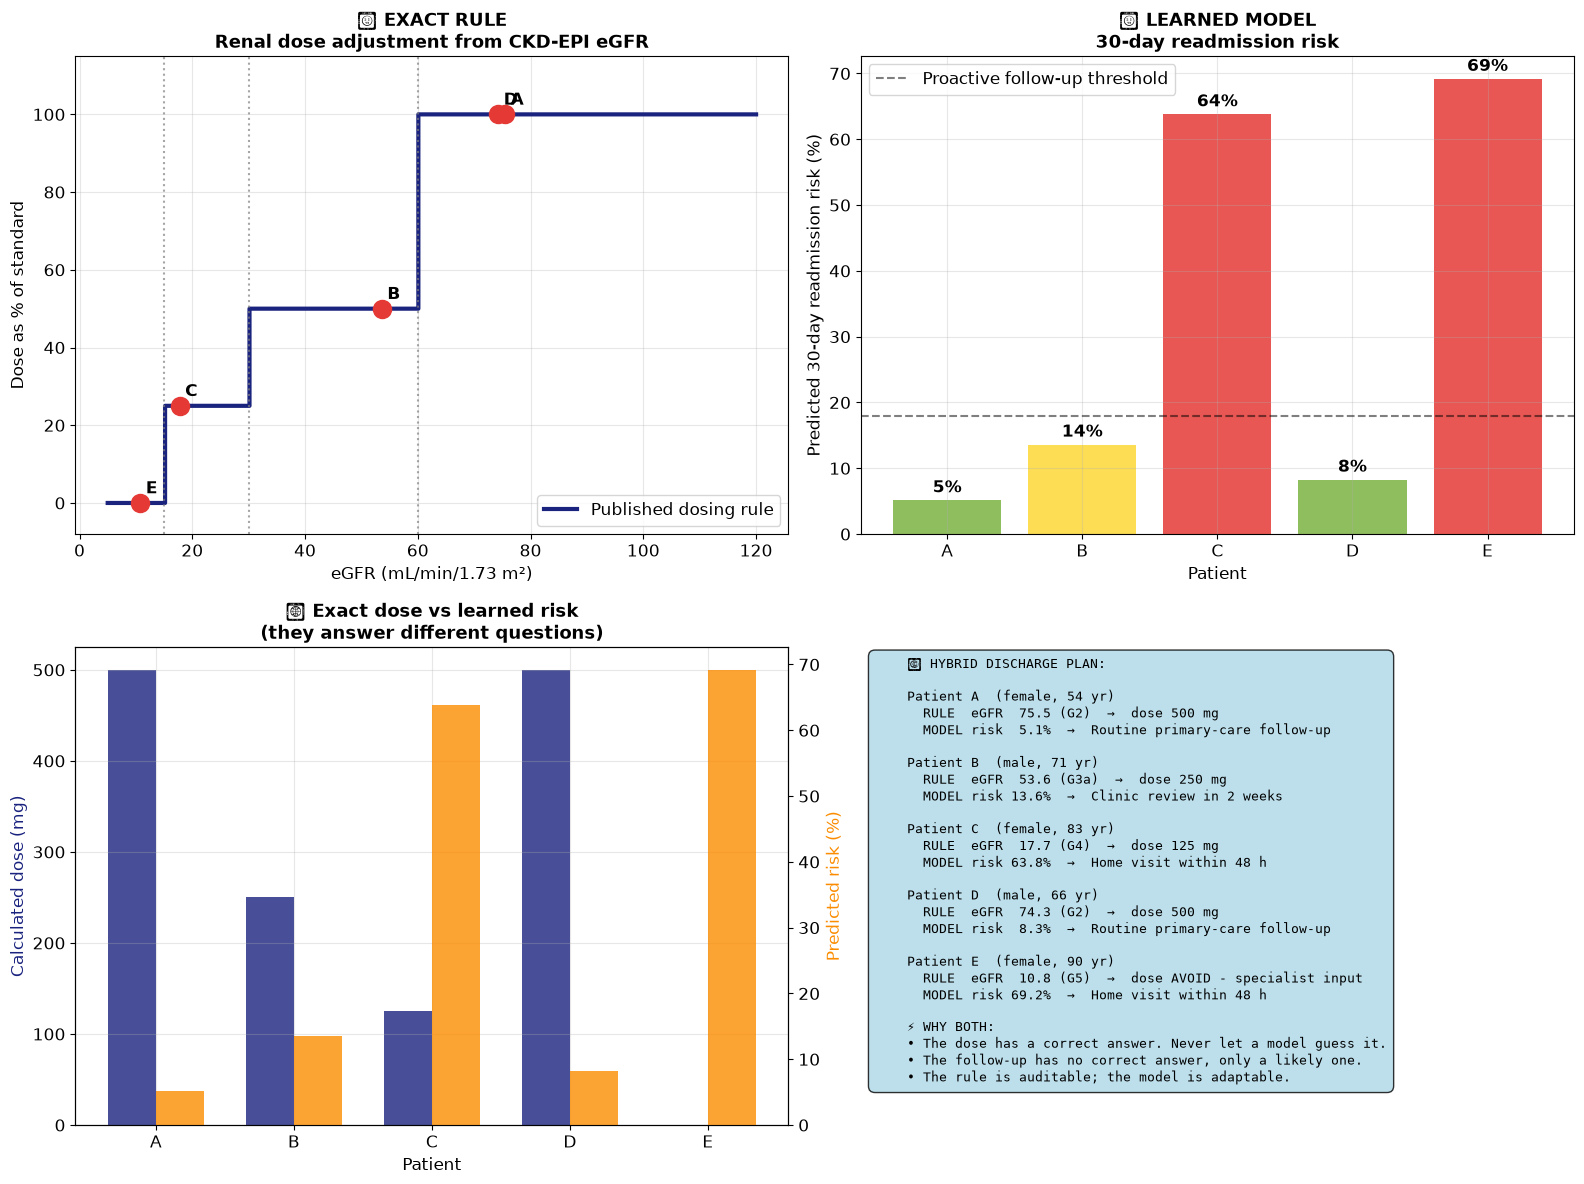

🚀 HYBRID DECISION SUPPORT DEMONSTRATION COMPLETE!

💡 Key Takeaway: the exact rule and the learned model answer different questions.
   Combining them gives a safer and more useful system than either alone.


In [10]:
# Hybrid Clinical Decision Support Example
def hybrid_clinical_decision_support_demo():
    """
    Demonstrate the hybrid approach: an exact rule for dosing, a learned model for risk.
    """
    # Five simulated patients ready for discharge on a renally cleared drug
    discharge_cohort = pd.DataFrame({
        'patient': ['A', 'B', 'C', 'D', 'E'],
        'sex': ['Female', 'Male', 'Female', 'Male', 'Female'],
        'age': [54, 71, 83, 66, 90],
        'creatinine': [80, 124, 230, 97, 336],   # µmol/L
        'comorbidity_count': [1, 3, 6, 2, 7],
        'prior_admissions_12mo': [0, 1, 3, 0, 4],
        'index_los_days': [3.0, 6.0, 11.0, 4.0, 14.0],
        'discharge_destination': [0, 1, 2, 0, 2],
        'medication_count': [4, 9, 15, 6, 18],
        'social_support_score': [8.5, 6.0, 3.0, 7.5, 2.0],
        'frailty_index': [0.10, 0.35, 0.72, 0.22, 0.88],
    })

    # ---------------- EXPLICIT PROGRAMMING: the exact renal dosing rule -------------
    def renal_dose_fraction(egfr):
        """
        Published renal dose adjustment for a renally cleared drug.
        This is a rule, not a prediction: the same eGFR always gives the same dose.
        """
        if egfr >= 60:
            return 1.00
        if egfr >= 30:
            return 0.50
        if egfr >= 15:
            return 0.25
        return 0.00      # contraindicated; needs specialist input

    STANDARD_DOSE_MG = 500

    discharge_cohort['egfr'] = [
        calculate_egfr(row.creatinine, row.age, row.sex)
        for row in discharge_cohort.itertuples()
    ]
    discharge_cohort['dose_fraction'] = discharge_cohort['egfr'].apply(renal_dose_fraction)
    discharge_cohort['dose_mg'] = discharge_cohort['dose_fraction'] * STANDARD_DOSE_MG

    # ---------------- MACHINE LEARNING: the learned readmission risk ---------------
    risk_model = RandomForestRegressor(n_estimators=100, random_state=42)
    risk_model.fit(df_patients[READMISSION_FEATURES], df_patients['readmission_risk_pct'])
    discharge_cohort['readmission_risk_pct'] = risk_model.predict(
        discharge_cohort[READMISSION_FEATURES]
    )

    def follow_up_plan(risk):
        """The learned score decides how much follow-up each patient gets."""
        if risk >= 30:
            return 'Home visit within 48 h'
        if risk >= 18:
            return 'Nurse phone call within 72 h'
        if risk >= 10:
            return 'Clinic review in 2 weeks'
        return 'Routine primary-care follow-up'

    discharge_cohort['follow_up'] = discharge_cohort['readmission_risk_pct'].apply(follow_up_plan)

    # Visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

    # 1. The exact rule, drawn as the step function it is
    egfr_axis = np.linspace(5, 120, 600)
    dose_axis = [renal_dose_fraction(g) * 100 for g in egfr_axis]
    ax1.step(egfr_axis, dose_axis, where='post', color='#1a237e', linewidth=3,
             label='Published dosing rule')
    for row in discharge_cohort.itertuples():
        ax1.plot(row.egfr, row.dose_fraction * 100, 'o', markersize=13, color='#e53935', zorder=5)
        ax1.annotate(row.patient, xy=(row.egfr, row.dose_fraction * 100),
                     xytext=(4, 7), textcoords='offset points', fontsize=12, fontweight='bold')

    for boundary in (15, 30, 60):
        ax1.axvline(x=boundary, color='gray', linestyle=':', alpha=0.7)
    ax1.set_xlabel('eGFR (mL/min/1.73 m²)')
    ax1.set_ylabel('Dose as % of standard')
    ax1.set_ylim(-8, 115)
    ax1.set_title('🧮 EXACT RULE\nRenal dose adjustment from CKD-EPI eGFR',
                  fontsize=13, fontweight='bold')
    ax1.legend(loc='lower right')
    ax1.grid(True, alpha=0.3)

    # 2. The learned component
    risk_colors = ['#e53935' if r >= 30 else '#fb8c00' if r >= 18 else '#fdd835' if r >= 10 else '#7cb342'
                   for r in discharge_cohort['readmission_risk_pct']]
    bars = ax2.bar(discharge_cohort['patient'], discharge_cohort['readmission_risk_pct'],
                   color=risk_colors, alpha=0.85)
    ax2.axhline(y=18, color='black', linestyle='--', alpha=0.5, label='Proactive follow-up threshold')
    ax2.set_xlabel('Patient')
    ax2.set_ylabel('Predicted 30-day readmission risk (%)')
    ax2.set_title('🤖 LEARNED MODEL\n30-day readmission risk', fontsize=13, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    for bar, value in zip(bars, discharge_cohort['readmission_risk_pct']):
        ax2.text(bar.get_x() + bar.get_width() / 2., bar.get_height() + 0.6,
                 f'{value:.0f}%', ha='center', va='bottom', fontweight='bold')

    # 3. The two components side by side
    x = np.arange(len(discharge_cohort))
    width = 0.35

    ax3.bar(x - width / 2, discharge_cohort['dose_mg'], width, label='Dose (mg)',
            alpha=0.8, color='#1a237e')
    ax3_twin = ax3.twinx()
    ax3_twin.bar(x + width / 2, discharge_cohort['readmission_risk_pct'], width,
                 label='Readmission risk (%)', alpha=0.8, color='#fb8c00')

    ax3.set_xlabel('Patient')
    ax3.set_ylabel('Calculated dose (mg)', color='#1a237e')
    ax3_twin.set_ylabel('Predicted risk (%)', color='#fb8c00')
    ax3.set_title('📊 Exact dose vs learned risk\n(they answer different questions)',
                  fontsize=13, fontweight='bold')
    ax3.set_xticks(x)
    ax3.set_xticklabels(discharge_cohort['patient'])
    ax3.grid(True, alpha=0.3)

    # 4. The combined care plan
    ax4.axis('off')

    plan_lines = ["    🎯 HYBRID DISCHARGE PLAN:", ""]
    for row in discharge_cohort.itertuples():
        code, label, _ = ckd_stage(row.egfr)
        dose_text = f"{row.dose_mg:.0f} mg" if row.dose_mg > 0 else "AVOID - specialist input"
        plan_lines.append(f"    Patient {row.patient}  ({row.sex.lower()}, {row.age} yr)")
        plan_lines.append(f"      RULE  eGFR {row.egfr:5.1f} ({code})  →  dose {dose_text}")
        plan_lines.append(f"      MODEL risk {row.readmission_risk_pct:4.1f}%  →  {row.follow_up}")
        plan_lines.append("")

    plan_lines += [
        "    ⚡ WHY BOTH:",
        "    • The dose has a correct answer. Never let a model guess it.",
        "    • The follow-up has no correct answer, only a likely one.",
        "    • The rule is auditable; the model is adaptable.",
    ]

    ax4.text(0.02, 0.98, "\n".join(plan_lines), transform=ax4.transAxes, fontsize=9.5,
             verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightblue", alpha=0.8))

    plt.tight_layout()
    plt.show()

    print("🚀 HYBRID DECISION SUPPORT DEMONSTRATION COMPLETE!")
    print("\n💡 Key Takeaway: the exact rule and the learned model answer different questions.")
    print("   Combining them gives a safer and more useful system than either alone.")


print("🚀 Hybrid Clinical Decision Support Demo")
print("See how an exact dosing rule and a learned risk score work together:")

hybrid_clinical_decision_support_demo()


---
# Part 5: Interactive Problem Classification

Now it's your turn. Let's practise deciding whether a clinical problem should be **calculated**
with an explicit rule or **learned** from data.


In [11]:
# Interactive problem classification exercise
clinical_problems = {
    'Calculating body mass index': {
        'correct_approach': 'Explicit Programming',
        'explanation': 'BMI is weight in kilograms divided by height in metres squared. It is a definition, not an estimate. Every calculator in the world must return the same number.',
        'factors': ['Defined by formula', 'Two inputs only', 'Must be reproducible', 'Deterministic']
    },
    'Predicting 30-day readmission': {
        'correct_approach': 'Machine Learning',
        'explanation': 'Readmission depends on comorbidity burden, prior utilization, frailty, polypharmacy, discharge destination and social support, all interacting differently in every patient. No committee has ever agreed a formula, but the pattern is visible in historical discharge records.',
        'factors': ['Many interacting variables', 'No published equation', 'Historical records available', 'Approximate answer is useful']
    },
    'Calculating estimated GFR from creatinine': {
        'correct_approach': 'Explicit Programming',
        'explanation': 'The CKD-EPI 2021 equation was derived and validated once, and is now applied identically everywhere. Given creatinine, age and sex the answer is fixed, which is exactly what drug dosing requires.',
        'factors': ['Published validated equation', 'Drives dosing decisions', 'Must be reproducible', 'Deterministic']
    },
    'Predicting sepsis onset hours in advance': {
        'correct_approach': 'Machine Learning',
        'explanation': 'Early sepsis shows up as a subtle drift across heart rate, blood pressure, respiratory rate, temperature and laboratory results over hours. The signature differs between patients and no threshold rule captures it, but models trained on monitoring data detect it earlier than rules do.',
        'factors': ['Subtle multi-channel patterns', 'Time-series signal', 'Individual variation', 'Earlier warning is valuable']
    },
    'Calculating an IV infusion drip rate': {
        'correct_approach': 'Explicit Programming',
        'explanation': 'Drops per minute equals volume times the drop factor divided by time. It is arithmetic, it is safety-critical, and a nurse must be able to check it by hand.',
        'factors': ['Simple arithmetic', 'Safety critical', 'Must be hand-checkable', 'Deterministic']
    },
    'Predicting clinic no-shows': {
        'correct_approach': 'Machine Learning',
        'explanation': 'Whether someone attends depends on travel distance, appointment lead time, weather, past attendance, deprivation, clinic and time of day. These interact in ways no policy could enumerate, but booking systems hold years of data on exactly this.',
        'factors': ['Behavioural and social factors', 'Many weak predictors', 'Large historical dataset', 'Approximate answer is useful']
    },
    'Calculating an Apgar score': {
        'correct_approach': 'Explicit Programming',
        'explanation': 'Apgar is a defined rubric: five components, each scored 0, 1 or 2, summed. Two clinicians observing the same newborn should record the same score. It is a protocol, not a prediction.',
        'factors': ['Defined scoring rubric', 'Fixed components', 'Reproducible by protocol', 'Deterministic']
    },
    'Predicting length of stay at admission': {
        'correct_approach': 'Machine Learning',
        'explanation': 'Length of stay depends on diagnosis, comorbidities, complications that have not happened yet, the availability of a rehabilitation bed and social circumstances. Bed managers need a forecast, not a certainty, and past admissions contain the pattern.',
        'factors': ['Many interacting variables', 'Operational forecasting', 'Historical data available', 'Uncertainty is acceptable']
    },
    'Calculating the corrected QT interval': {
        'correct_approach': 'Explicit Programming',
        'explanation': "Bazett's formula divides the measured QT by the square root of the RR interval in seconds. It is a published correction that every ECG machine applies identically.",
        'factors': ['Published formula', 'Drives prescribing decisions', 'Reproducible', 'Deterministic']
    },
    'Interpreting a chest radiograph': {
        'correct_approach': 'Machine Learning',
        'explanation': 'No one can write down the rule that distinguishes consolidation from atelectasis in pixels. Radiologists learn it from tens of thousands of examples, and so do convolutional models.',
        'factors': ['Perceptual pattern recognition', 'Impossible to specify in rules', 'Large labelled datasets', 'Learned from examples']
    },
    'Calculating body surface area for chemotherapy dosing': {
        'correct_approach': 'Explicit Programming',
        'explanation': 'The Mosteller formula, the square root of height in centimetres times weight in kilograms divided by 3600, is a published definition. Chemotherapy dosing depends on it being identical everywhere.',
        'factors': ['Published formula', 'Safety critical dosing', 'Must be reproducible', 'Deterministic']
    },
    'Assigning triage acuity in the emergency department': {
        'correct_approach': 'Machine Learning',
        'explanation': 'Experienced triage nurses combine presenting complaint, observations, appearance, history and a great deal of tacit knowledge. Models trained on past triage decisions and outcomes can support that judgement, but no rule set reproduces it.',
        'factors': ['Tacit expert judgement', 'Free text plus observations', 'Learned from past decisions', 'Decision support, not replacement']
    },
}

def interactive_problem_classifier(problem_selection='Random'):
    """
    Interactive exercise for classifying clinical problems
    """
    if problem_selection == 'Random':
        problem_name = np.random.choice(list(clinical_problems.keys()))
    else:
        problem_name = problem_selection

    problem = clinical_problems[problem_name]

    # Create visualization
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

    # 1. Problem statement
    ax1.axis('off')
    ax1.text(0.5, 0.72, '🤔 CLINICAL PROBLEM', ha='center', fontsize=16, fontweight='bold',
             transform=ax1.transAxes)
    ax1.text(0.5, 0.5, problem_name.upper(), ha='center', fontsize=12, fontweight='bold',
             transform=ax1.transAxes, wrap=True,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", alpha=0.9))
    ax1.text(0.5, 0.3, 'Should this be CALCULATED or LEARNED?', ha='center', fontsize=12,
             transform=ax1.transAxes)
    ax1.text(0.25, 0.1, '📐 CALCULATE\n(explicit rule)', ha='center', fontsize=12, fontweight='bold',
             transform=ax1.transAxes, color='blue',
             bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.7))
    ax1.text(0.75, 0.1, '🤖 LEARN\n(from data)', ha='center', fontsize=12, fontweight='bold',
             transform=ax1.transAxes, color='red',
             bbox=dict(boxstyle="round,pad=0.3", facecolor="lightcoral", alpha=0.7))

    # 2. Decision factors
    ax2.axis('off')
    ax2.text(0.5, 0.9, '🔍 DECISION FACTORS', ha='center', fontsize=14, fontweight='bold',
             transform=ax2.transAxes)

    factors_text = "\n".join([f"• {factor}" for factor in problem['factors']])
    ax2.text(0.05, 0.8, factors_text, transform=ax2.transAxes, fontsize=11, verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray", alpha=0.7))

    # 3. Correct answer and explanation
    ax3.axis('off')
    approach_color = 'lightblue' if problem['correct_approach'] == 'Explicit Programming' else 'lightcoral'
    approach_icon = '📐' if problem['correct_approach'] == 'Explicit Programming' else '🤖'

    ax3.text(0.5, 0.92, '✅ CORRECT APPROACH', ha='center', fontsize=14, fontweight='bold',
             transform=ax3.transAxes)
    ax3.text(0.5, 0.74, f'{approach_icon} {problem["correct_approach"].upper()}',
             ha='center', fontsize=16, fontweight='bold',
             transform=ax3.transAxes,
             bbox=dict(boxstyle="round,pad=0.5", facecolor=approach_color, alpha=0.9))

    wrapped = textwrap.fill(problem['explanation'], width=64)
    ax3.text(0.03, 0.55, wrapped, transform=ax3.transAxes, fontsize=10,
             verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow", alpha=0.8))

    # 4. Summary statistics
    explicit_count = sum(1 for p in clinical_problems.values() if p['correct_approach'] == 'Explicit Programming')
    ml_count = len(clinical_problems) - explicit_count

    approaches = ['Calculate\n(explicit rule)', 'Learn\n(from data)']
    counts = [explicit_count, ml_count]
    colors = ['lightblue', 'lightcoral']

    ax4.pie(counts, labels=approaches, colors=colors, autopct='%1.0f%%',
            startangle=90, textprops={'fontsize': 12})
    ax4.set_title('Distribution of Approaches\nin These Clinical Problems', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

    print("\n💡 KEY LEARNING:")
    if problem['correct_approach'] == 'Explicit Programming':
        print("   📐 This problem has a defined rule and demands a reproducible answer.")
        print("   🎯 Calculate when the physiology or the definition is already settled.")
    else:
        print("   🤖 This problem involves too many interacting factors for any rule set.")
        print("   🎯 Learn when the pattern exists in the data but nobody can write it down.")

    print("\n🔄 Try different problems to practise your classification skills!")

# Create dropdown with all problems
problem_options = ['Random'] + list(clinical_problems.keys())

print("🎓 Interactive Problem Classification Exercise")
print("Practise identifying when to calculate and when to learn:")

interact(interactive_problem_classifier,
         problem_selection=Dropdown(options=problem_options, value='Random',
                                   description='Problem:'));


🎓 Interactive Problem Classification Exercise
Practise identifying when to calculate and when to learn:


interactive(children=(Dropdown(description='Problem:', options=('Random', 'Calculating body mass index', 'Pred…

---
# Part 6: Key Takeaways for Clinical Teams

Let's summarize the insights for clinicians, informaticians and health-system leaders.


🎓 Final Takeaways and Action Items
Your roadmap to using AI and ML in clinical care:


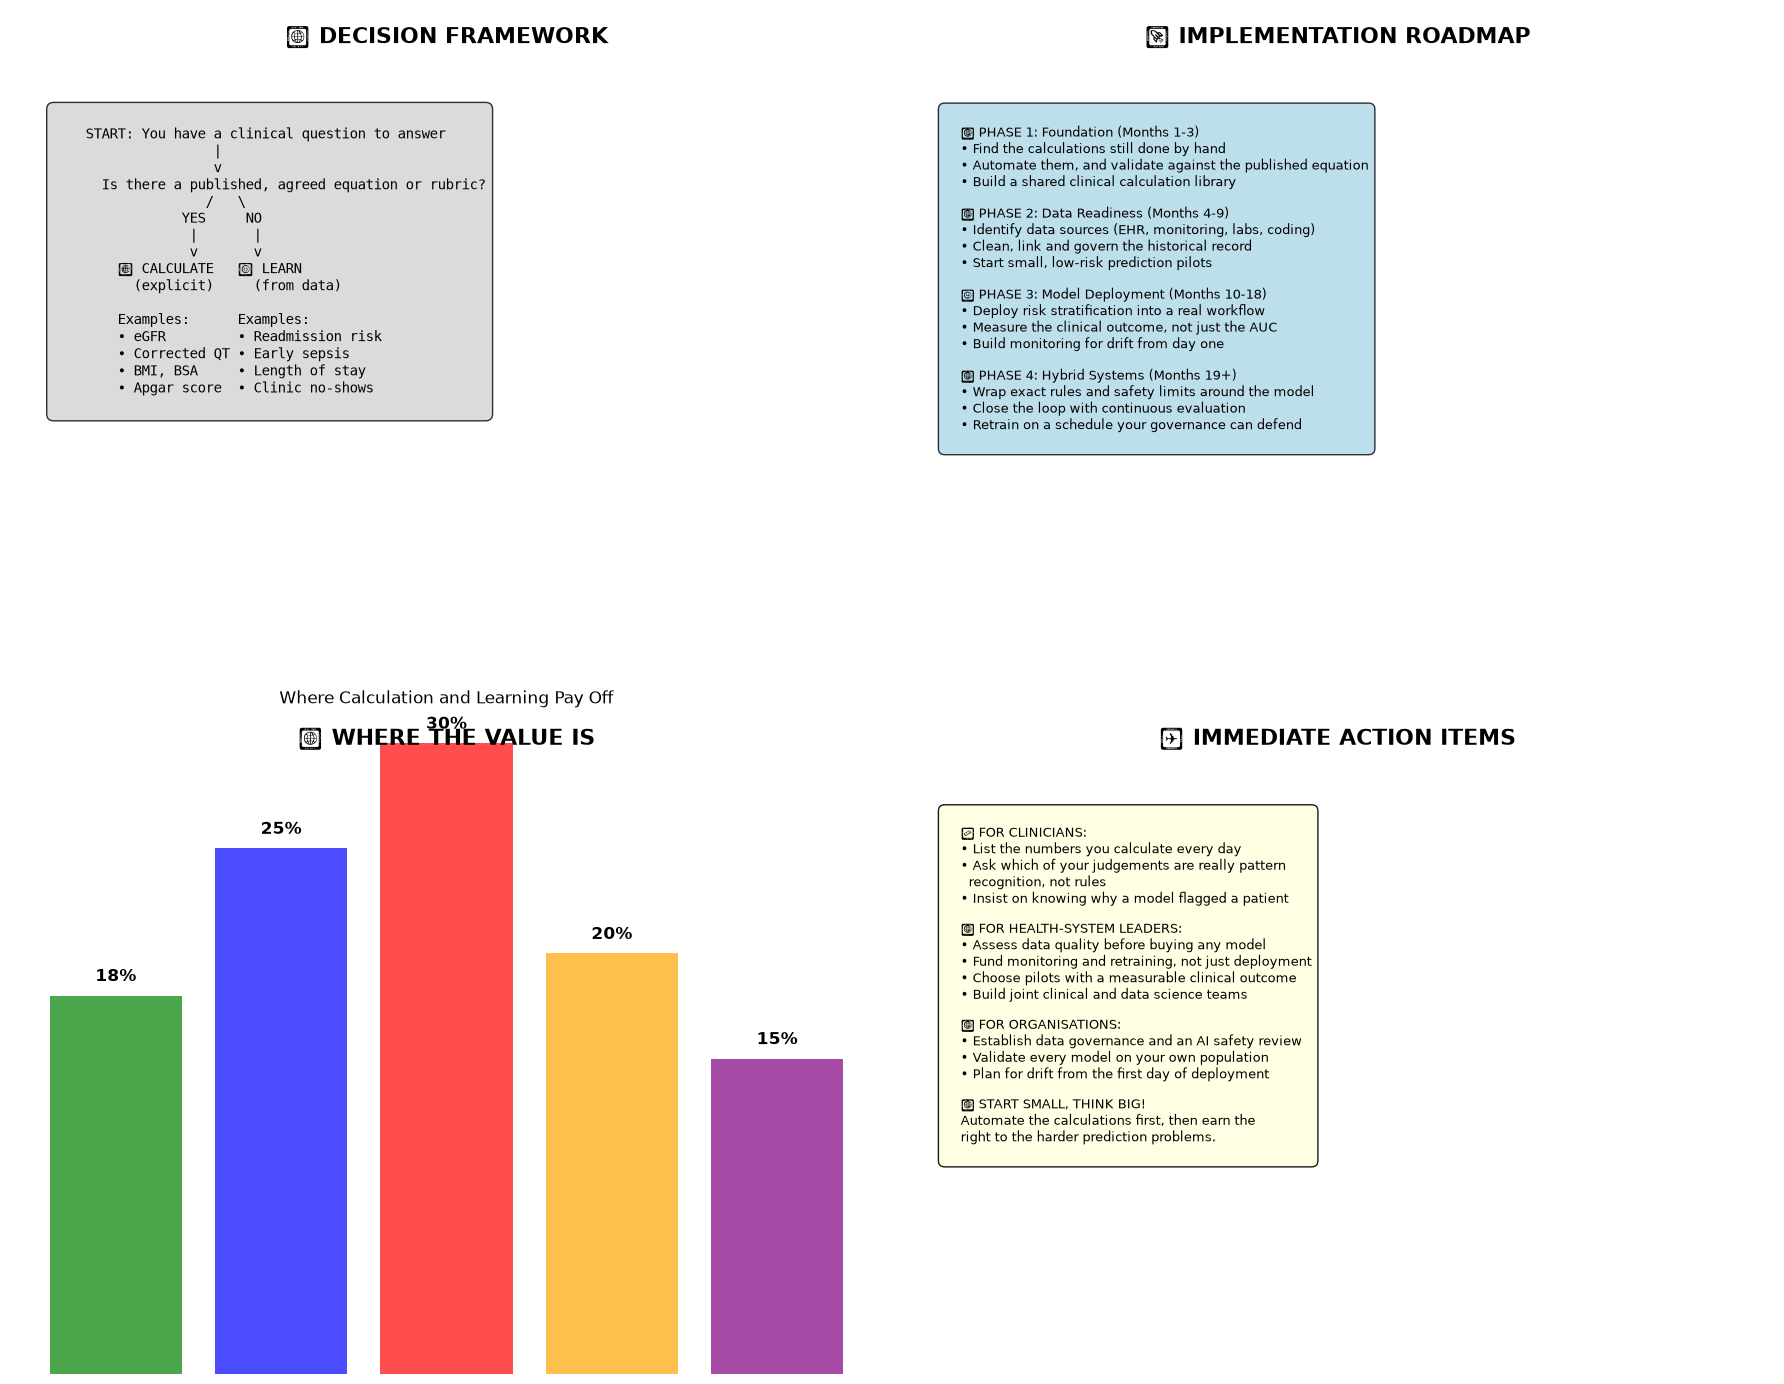

🎓 WORKSHOP COMPLETE! 🎓

🌟 You now understand the fundamental difference between:
   📐 EXPLICIT PROGRAMMING: When we know the rule
   🤖 MACHINE LEARNING: When we learn from patterns
   🚀 HYBRID APPROACHES: Combining both for safer, better systems

💡 Key Insight: both approaches are essential in a modern health system!

🎯 Next Steps: start identifying opportunities in your own practice!


In [12]:
# Final summary and takeaways
def display_final_takeaways():
    """
    Display comprehensive takeaways for clinicians and health-system leaders
    """
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 14))

    # 1. When to use each approach - Decision tree style
    ax1.axis('off')
    ax1.text(0.5, 0.95, '🌳 DECISION FRAMEWORK', ha='center', fontsize=16, fontweight='bold',
             transform=ax1.transAxes)

    decision_text = """
    START: You have a clinical question to answer
                    |
                    v
      Is there a published, agreed equation or rubric?
                   /   \\
                YES     NO
                 |       |
                 v       v
        📐 CALCULATE   🤖 LEARN
          (explicit)     (from data)

        Examples:      Examples:
        • eGFR         • Readmission risk
        • Corrected QT • Early sepsis
        • BMI, BSA     • Length of stay
        • Apgar score  • Clinic no-shows
    """

    ax1.text(0.05, 0.85, decision_text, transform=ax1.transAxes, fontsize=10,
             verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray", alpha=0.8))

    # 2. Implementation roadmap
    ax2.axis('off')
    ax2.text(0.5, 0.95, '🚀 IMPLEMENTATION ROADMAP', ha='center', fontsize=16, fontweight='bold',
             transform=ax2.transAxes)

    roadmap_text = """
    🎯 PHASE 1: Foundation (Months 1-3)
    • Find the calculations still done by hand
    • Automate them, and validate against the published equation
    • Build a shared clinical calculation library

    📊 PHASE 2: Data Readiness (Months 4-9)
    • Identify data sources (EHR, monitoring, labs, coding)
    • Clean, link and govern the historical record
    • Start small, low-risk prediction pilots

    🤖 PHASE 3: Model Deployment (Months 10-18)
    • Deploy risk stratification into a real workflow
    • Measure the clinical outcome, not just the AUC
    • Build monitoring for drift from day one

    🏆 PHASE 4: Hybrid Systems (Months 19+)
    • Wrap exact rules and safety limits around the model
    • Close the loop with continuous evaluation
    • Retrain on a schedule your governance can defend
    """

    ax2.text(0.05, 0.85, roadmap_text, transform=ax2.transAxes, fontsize=9,
             verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightblue", alpha=0.8))

    # 3. Where the value is
    ax3.axis('off')
    ax3.text(0.5, 0.95, '💰 WHERE THE VALUE IS', ha='center', fontsize=16, fontweight='bold',
             transform=ax3.transAxes)

    impact_areas = ['Avoidable\nReadmissions', 'Earlier\nDeterioration\nDetection',
                    'Medication\nSafety', 'Flow and\nCapacity', 'Clinician\nTime Saved']
    impact_values = [18, 25, 30, 20, 15]  # Illustrative percentage improvements
    colors = ['green', 'blue', 'red', 'orange', 'purple']

    bars = ax3.bar(range(len(impact_areas)), impact_values, color=colors, alpha=0.7)
    ax3.set_xticks(range(len(impact_areas)))
    ax3.set_xticklabels(impact_areas, fontsize=8)
    ax3.set_ylabel('Illustrative improvement (%)')
    ax3.set_title('Where Calculation and Learning Pay Off', fontsize=12)
    ax3.grid(True, alpha=0.3)

    for bar, value in zip(bars, impact_values):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{value}%', ha='center', va='bottom', fontweight='bold')

    # 4. Action items
    ax4.axis('off')
    ax4.text(0.5, 0.95, '✅ IMMEDIATE ACTION ITEMS', ha='center', fontsize=16, fontweight='bold',
             transform=ax4.transAxes)

    action_text = """
    🩺 FOR CLINICIANS:
    • List the numbers you calculate every day
    • Ask which of your judgements are really pattern
      recognition, not rules
    • Insist on knowing why a model flagged a patient

    👔 FOR HEALTH-SYSTEM LEADERS:
    • Assess data quality before buying any model
    • Fund monitoring and retraining, not just deployment
    • Choose pilots with a measurable clinical outcome
    • Build joint clinical and data science teams

    🏥 FOR ORGANISATIONS:
    • Establish data governance and an AI safety review
    • Validate every model on your own population
    • Plan for drift from the first day of deployment

    🎯 START SMALL, THINK BIG!
    Automate the calculations first, then earn the
    right to the harder prediction problems.
    """

    ax4.text(0.05, 0.85, action_text, transform=ax4.transAxes, fontsize=9,
             verticalalignment='top',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lightyellow", alpha=0.9))

    plt.tight_layout()
    plt.show()

    print("🎓 WORKSHOP COMPLETE! 🎓")
    print("\n🌟 You now understand the fundamental difference between:")
    print("   📐 EXPLICIT PROGRAMMING: When we know the rule")
    print("   🤖 MACHINE LEARNING: When we learn from patterns")
    print("   🚀 HYBRID APPROACHES: Combining both for safer, better systems")
    print("\n💡 Key Insight: both approaches are essential in a modern health system!")
    print("\n🎯 Next Steps: start identifying opportunities in your own practice!")


print("🎓 Final Takeaways and Action Items")
print("Your roadmap to using AI and ML in clinical care:")

display_final_takeaways()


---
# Conclusion

## 🎯 What You've Learned

Congratulations! You've now experienced the distinction that sits underneath all of artificial
intelligence and machine learning in healthcare:

### 📐 **Explicit Programming** (Calculate)
- **When to use**: a published equation or rubric already settles the answer
- **Examples**: eGFR by CKD-EPI 2021, corrected QT by Bazett, BMI, body surface area, Apgar
- **Advantages**: exact, reproducible, auditable, defensible to a regulator
- **Limitations**: only works when the rule is already known and stable

### 🤖 **Machine Learning** (Learn)
- **When to use**: too many interacting factors for any rule set
- **Examples**: 30-day readmission, early sepsis detection, length of stay, clinic no-shows
- **Advantages**: handles complexity, finds patterns nobody wrote down, adapts to new data
- **Limitations**: approximate, needs good data, harder to explain, and it **drifts**

### 🚀 **Hybrid Approach** (Both)
- **Combine**: exact rules and hard safety limits around a learned risk score
- **Result**: systems that are both safe and useful
- **Example from this notebook**: the renal dose is calculated; the follow-up intensity is learned

## 🩺 The Real Lesson

The failure mode in clinical AI is not usually a bad model. It is using the wrong tool:

- Reaching for a model where a published equation already gives the right answer — and losing
  reproducibility, auditability and trust for nothing
- Reaching for a rule where the pattern is genuinely too complex — and getting a checklist that
  fires on everyone and helps no one
- Deploying a learned model and then never looking at it again, while the population drifts
  underneath it

## 🎯 Your Next Steps

1. **Look at your own work** — which answers are defined, and which are really predictions?
2. **Start small** — automate the calculations you already trust
3. **Get the data in order** — most clinical ML projects fail on data quality, not algorithms
4. **Build skills** — basic data literacy goes a long way in a clinical team
5. **Think hybrid** — put the exact rule where it belongs, and let the model work around it

---

*Welcome to the practical side of clinical AI! 🩺📊*
